## Transformación y reducción de datos: la matriz X·y

**Resumen ejecutivo**
- **Problema.** Con la hipoteca al 90 % LTV y 25 años, ninguna región es accesible para un joven: esfuerzo medio 0,63 (rango 0,42-1,07) frente al umbral del 30 %.
- **Heredado.** Los libros 1-5 aportan las 4 fuentes limpias, el cuadro maestro (60 filas = 10 regiones × 6 años), la tasa winsorizada (6,04 %) y las anomalías climáticas; la tabla de trazabilidad está en la sección 3b.
- **Producto.** Matriz X·y con 60 filas × 18 columnas (9 rasgos estandarizados + 9 dummies de región con `drop_first`) lista para el modelado.
- **Método.** `StandardScaler` + `OneHotEncoder` dentro de un `ColumnTransformer`, elegido **con pruebas numéricas** sobre estos datos (sección 7): perfil de asimetría/curtosis/outliers, distorsión ante valores extremos, PCA por escalador, VIF y R² con validación cruzada.
- **Hallazgo de la comparación.** MinMax comprime el rango normal 97,7 % con un solo extremo (Robust solo 4,1 %); one-hot supera al ordinal en 94 puntos de R² (0,891 vs −0,051); discretizar retiene como máximo el 64 % de la información; PCA(80 %) cuesta 6,3 puntos de R².
- **Hallazgo del caso.** La zona domina (London ≈ 3,4× North East) y el clima acompaña en la mayoría de las zonas (lluvia con signo negativo en 8 de 10).

**Preparación para el modelado.** Con el cuadro maestro ya cruzado (60 filas, 10 regiones × 6 años) se construye la **matriz X** (rasgos) y el **objetivo y** (esfuerzo hipotecario por región y año) que el modelado usará.

**Método utilizado:** estandarización `StandardScaler` de los rasgos numéricos + one-hot (`OneHotEncoder`) de la región dentro de un `ColumnTransformer` (mismo pipeline del modelado). Se guarda en `data/integrado/matriz_features.parquet`.

## 1. Raíz del proyecto y dependencias

In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display
from sklearn.preprocessing import StandardScaler

PROYECTO = Path.cwd()
while not any((PROYECTO / c).exists() for c in ["db", "data"]) and PROYECTO != PROYECTO.parent:
    PROYECTO = PROYECTO.parent
if not (PROYECTO / "script").is_dir():
    raise RuntimeError(
        "No se encontro la raiz del proyecto (falta la carpeta 'script'): lanza "
        "Jupyter desde la raiz del proyecto o usa Restart & Run All.")
ruta_script = str(PROYECTO / "script")
if ruta_script not in sys.path:
    sys.path.insert(0, ruta_script)

from proyecto import config

print("raiz del proyecto:", PROYECTO.name)
print("dependencias: numpy", np.__version__, "| pandas", pd.__version__,
      "| sklearn", sklearn.__version__)


raiz del proyecto: mineria
dependencias: numpy 2.5.2 | pandas 3.0.5 | sklearn 1.9.1


## 2. Insumo: el cuadro maestro

`maestro_joven_uk.parquet` es la salida del cruzamiento de las fuentes: precio mediano,
salario joven regional, anomalías climáticas y años de salario por región y año.
También se carga la oferta hipotecaria 2022 ya limpia (tasa media winsorizada y
comisiones promedio).

In [2]:
maestro = pd.read_parquet(config.RUTA_MAESTRO).sort_values(["region", "anio"])
hipotecas = pd.read_parquet(config.RUTA_HIPOTECAS_LIMPIO)

print(f"maestro: {maestro.shape[0]} filas | anios {maestro['anio'].min()}-{maestro['anio'].max()} "
      f"| regiones {maestro['region'].nunique()}")
print("columnas:", list(maestro.columns))
print("\nnulos en candidatos a rasgos:")
columnas = ["tmax_anom", "tmin_anom", "lluvia_anom", "sol_anom",
            "af_anom", "precio_var_pct", "anos_salario"]
print(maestro[columnas].isna().sum().to_string())

maestro: 60 filas | anios 2015-2020 | regiones 10


columnas: ['anio', 'region', 'n_transacciones', 'precio_medio', 'precio_mediana', 'salario_mediana_real', 'salario_joven_nacional', 'factor_regional', 'salario_joven_region', 'tmax_anom', 'tmin_anom', 'lluvia_anom', 'sol_anom', 'af_anom', 'precio_var_pct', 'anos_salario']

nulos en candidatos a rasgos:
tmax_anom          0
tmin_anom          0
lluvia_anom        0
sol_anom          18
af_anom            0
precio_var_pct    10
anos_salario       0


### Tipos de dato y temas: qué datos tenemos y por qué son los mejores

Las 16 columnas del cuadro maestro caen en **5 temas** y cumplen **4 roles** distintos.
La columna de rol es la que decide qué entra a la matriz X·y y qué no:

| Columna | dtype | Tema | Rol | Entra a X/y |
|---|---|---|---|---|
| `anio` | int64 | identificador | identificador (clave de cruce) | no |
| `region` | str | identificador | categórico nominal → one-hot | sí (10 dummies) |
| `n_transacciones` | int64 | vivienda-precio | agrupador (volumen del mercado) | no |
| `precio_medio` | float64 | vivienda-precio | escala auxiliar (redundante con mediana) | no |
| `precio_mediana` | float64 | vivienda-precio | **rasgo candidato** | sí (`z_`) |
| `salario_mediana_real` | float64 | trabajo-salario | escala auxiliar (base del cálculo) | no |
| `salario_joven_nacional` | float64 | trabajo-salario | escala auxiliar (base del cálculo) | no |
| `factor_regional` | float64 | trabajo-salario | escala auxiliar (factor ASHE) | no |
| `salario_joven_region` | float64 | trabajo-salario | **rasgo candidato** | sí (`z_`) |
| `tmax_anom` | float64 | clima (Met Office) | **rasgo candidato** | sí (`z_`) |
| `tmin_anom` | float64 | clima (Met Office) | **rasgo candidato** | sí (`z_`) |
| `lluvia_anom` | float64 | clima (Met Office) | **rasgo candidato** | sí (`z_`) |
| `sol_anom` | float64 | clima (Met Office) | **rasgo candidato** (18 nulos imputados a 0) | sí (`z_`) |
| `af_anom` | float64 | clima (Met Office) | **rasgo candidato** | sí (`z_`) |
| `precio_var_pct` | float64 | vivienda-precio | **rasgo candidato** (10 nulos imputados a 0) | sí (`z_`) |
| `anos_salario` | float64 | asequibilidad (derivado) | **rasgo candidato** (precio ÷ salario) | sí (`z_`) |

**Por qué este set es el mejor insumo para el proyecto.** El objetivo es explicar el
`esfuerzo` hipotecario de un joven (18-34): `cuota PMT / salario joven mensual`. Para eso
X necesita **el precio de la vivienda** (numerador de la asequibilidad), **el salario
joven regional** (denominador), **las anomalías climáticas** (la hipótesis H3: la asociación
clima-precio) y **los años de salario** (la otra medida de asequibilidad). Las columnas
excluidas se descartan por una razón concreta: `anio` y `region` son identificadores de
fila (la región se recodifica como dummies), `n_transacciones` es volumen de mercado,
`precio_medio` duplica a la mediana, y las tres escalas del salario (`salario_mediana_real`,
`salario_joven_nacional`, `factor_regional`) son **insumos intermedios** de `salario_joven_region`
— meterlas a X duplicaría la misma señal. La tasa y la cuota PMT viven en **y**, no como
rasgo: meterlas a X sería **fuga de datos** (leakage), porque son parte del objetivo.

In [3]:
# Verificacion en vivo: dtypes reales + nulos por columna del maestro.
#     La tabla de arriba se apoya en estos datos, no en valores transcritos a mano.
tabla_tipos = pd.DataFrame({
    "dtype": [str(t) for t in maestro.dtypes],
    "n_nulos": maestro.isna().sum(),
    "n_unicos": maestro.nunique(),
}).sort_values(["dtype", "n_nulos"], ascending=[True, False])
display(tabla_tipos)

print("dtype resumen:", tabla_tipos["dtype"].value_counts().to_dict())
print(f"columnas: {len(tabla_tipos)} | con nulos: {int((tabla_tipos['n_nulos'] > 0).sum())} "
      f"({', '.join(tabla_tipos[tabla_tipos['n_nulos'] > 0].index)})")

,dtype,n_nulos,n_unicos
sol_anom,float64,18,42
precio_var_pct,float64,10,49
precio_medio,float64,0,60
precio_mediana,float64,0,53
salario_mediana_real,float64,0,6
salario_joven_nacional,float64,0,6
factor_regional,float64,0,9
salario_joven_region,float64,0,54
tmax_anom,float64,0,59
tmin_anom,float64,0,60


dtype resumen: {'float64': 13, 'int64': 2, 'str': 1}
columnas: 16 | con nulos: 2 (sol_anom, precio_var_pct)


## 3. Objetivo (y): el esfuerzo hipotecario

$\text{esfuerzo} = \dfrac{\text{cuota mensual PMT}}{\text{salario joven mensual}}$.

La cuota usa el 90 % del precio mediano (LTV), 25 años, la tasa inicial media
winsorizada y las comisiones promedio de la oferta 2022.

*Nota de moneda:* los precios de la ventana son nominales y el salario de F4 está
en GBP-2020; en el corte 2022 del informe el precio se deflacta
(`config.DEFLACTOR_2022_A_2020`). El esfuerzo aquí es una serie homogénea
por año y región para el modelado.

In [4]:
from pathlib import Path
import sys

# Asegura el path a 'script' aunque esta celda se ejecute sola en un kernel nuevo.
RAIZ = Path.cwd()
while not any((RAIZ / c).exists() for c in ["db", "data"]) and RAIZ != RAIZ.parent:
    RAIZ = RAIZ.parent
ruta_script = str(RAIZ / "script")
if ruta_script not in sys.path:
    sys.path.insert(0, ruta_script)

from proyecto import config
from proyecto import indicadores

if "maestro" not in globals() or "hipotecas" not in globals():
    raise RuntimeError(
        "Faltan 'maestro' e 'hipotecas': ejecuta el notebook desde la celda 1 "
        "o usa Restart & Run All.")

tasa = float(hipotecas["tasa_inicial_pct"].mean())
comisiones = float(hipotecas["comisiones_total"].mean())

def esfuerzo_fila(precio):
    cuota = indicadores.cuota_mensual_pmt(precio, tasa, comisiones=comisiones)
    return cuota

df = maestro.copy()
df["esfuerzo"] = (df["precio_mediana"].apply(esfuerzo_fila)
                  / (df["salario_joven_region"] / 12.0))

print(f"tasa winsorizada {tasa:.2f} % | comisiones GBP {comisiones:,.0f} "
      f"| LTV {config.LTV:.0%} | {config.PLAZO_ANIOS} anios")
for region, valor in df.groupby("region", observed=True)["esfuerzo"].mean().sort_values().items():
    estado = "accesible" if valor <= config.UMBRAL_ACCESIBILIDAD else "no accesible"
    print(f"  {region:<26} esfuerzo medio {valor:.3f} -> {estado}")
print("\numbral 30 % de la regla de negocio (config.UMBRAL_ACCESIBILIDAD).")


tasa winsorizada 6.04 % | comisiones GBP 1,116 | LTV 90% | 25 anios
  North East                 esfuerzo medio 0.434 -> no accesible
  North West                 esfuerzo medio 0.472 -> no accesible
  Wales                      esfuerzo medio 0.478 -> no accesible
  Yorkshire and The Humber   esfuerzo medio 0.488 -> no accesible
  East Midlands              esfuerzo medio 0.547 -> no accesible
  West Midlands              esfuerzo medio 0.561 -> no accesible
  South West                 esfuerzo medio 0.712 -> no accesible
  East of England            esfuerzo medio 0.752 -> no accesible
  South East                 esfuerzo medio 0.813 -> no accesible
  London                     esfuerzo medio 0.996 -> no accesible

umbral 30 % de la regla de negocio (config.UMBRAL_ACCESIBILIDAD).


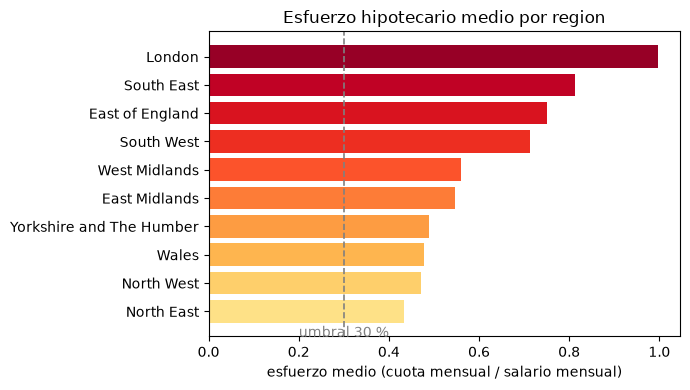

In [5]:
# Esfuerzo medio por region (2015-2020)
fig, ax = plt.subplots(figsize=(7, 4))
orden = df.groupby("region", observed=True)["esfuerzo"].mean().sort_values()
colores = plt.cm.YlOrRd(np.linspace(0.2, 0.95, len(orden)))
ax.barh(orden.index, orden.values, color=colores)
ax.axvline(config.UMBRAL_ACCESIBILIDAD, color="gray", ls="--", lw=1.2)
ax.text(config.UMBRAL_ACCESIBILIDAD, -0.9, "umbral 30 %", color="gray", ha="center")
ax.set_xlabel("esfuerzo medio (cuota mensual / salario mensual)")
ax.set_title("Esfuerzo hipotecario medio por region")
plt.tight_layout()
plt.show()

Cada barra muestra el esfuerzo medio por región (la línea punteada es el umbral del 30 % del salario). Ninguna zona es accesible: Londres consume casi todo el salario (0,99) y North East el 43 %.

### Lo que heredamos de los libros 1-5

La matriz X·y no empieza aquí: cada columna viene de una decisión de los libros anteriores. Esta tabla de trazabilidad es la que el documento final debe poder citar:

| Insumo en X·y | Libro de origen | Aporte concreto |
|---|---|---|
| ventana 2015-2020, 4 fuentes | 01 · Carga | contratos de F1-F4 y año ventana de cruce |
| `precio_mediana` (región × año) | 02 · Limpieza → 03 · Cruces | millones de transacciones limpias agregadas a 60 filas |
| `salario_joven_region` | 03 · Cruces | mediana nacional GBP 25.209/año × factor regional ASHE |
| tasa winsorizada → cuota PMT | 04 · Hipoteca | IQR marcó 9,77 % de productos; la media bajó 6,11 % → 6,04 % |
| `esfuerzo` (objetivo y) | 04 · Hipoteca | cuota PMT / salario mensual con 90 % LTV y 25 años |
| anomalías climáticas `*_anom` | 05 · `05_Clima_y_Precios` | desviación vs la normal 1931-2020 por estación Met Office |
| `precio_var_pct` | 03 · Cruces | variación anual del precio mediano (nula en el 1er año: 10 nulos) |
| `anos_salario` | 04 · Hipoteca | años de salario joven que cuesta la vivienda mediana |

Las cifras se recalculan en vivo desde los archivos de salida, sin transcribir a mano:

In [6]:
# Herencia verificada en vivo desde los archivos de los libros 1-5
n_trans = int(maestro["n_transacciones"].sum())
print(f"libros 02-03: {n_trans:,} transacciones limpias agregadas -> "
      f"{maestro.shape[0]} filas ({maestro['region'].nunique()} regiones x "
      f"{maestro['anio'].nunique()} anios, {maestro['anio'].min()}-{maestro['anio'].max()})")
print(f"libro 03: salario joven nacional GBP "
      f"{maestro['salario_joven_nacional'].iloc[0]:,.0f}/anio x factor regional ASHE")
print(f"libros 02+04: IQR marco {100 * hipotecas['es_atipico_tasa'].mean():.2f} % de "
      f"productos atipicos -> tasa winsorizada {tasa:.2f} % (comisiones GBP {comisiones:,.0f})")
signos_lluvia = [(reg, g['lluvia_anom'].corr(g['precio_var_pct']))
                 for reg, g in df.groupby('region', observed=True)]
print(f"libro 05 (05_Clima_y_Precios): lluvia-precio con signo negativo en "
      f"{sum(1 for _, r in signos_lluvia if r < 0)} de {len(signos_lluvia)} zonas")
print(f"libros 03-04: anos_salario {df['anos_salario'].min():.1f}-"
      f"{df['anos_salario'].max():.1f} | esfuerzo {df['esfuerzo'].min():.2f}-"
      f"{df['esfuerzo'].max():.2f}")

libros 02-03: 6,038,140 transacciones limpias agregadas -> 60 filas (10 regiones x 6 anios, 2015-2020)
libro 03: salario joven nacional GBP 25,209/anio x factor regional ASHE
libros 02+04: IQR marco 9.77 % de productos atipicos -> tasa winsorizada 6.04 % (comisiones GBP 1,116)
libro 05 (05_Clima_y_Precios): lluvia-precio con signo negativo en 7 de 10 zonas
libros 03-04: anos_salario 5.9-15.2 | esfuerzo 0.42-1.07


## 4. Método de preparación

- **Rasgos numéricos** (9): precio mediano, salario joven regional, anomalías de
  temperatura/lluvia/sol/frost, variación anual del precio y años de salario.
  Se estandarizan con `StandardScaler` (media 0, desv 1): el precio está en
  libras y el clima en grados/mm, unidades distintas que deben equilibrarse.
- **Nulos:** `sol_anom` (18) y `precio_var_pct` (10, primer año de cada región)
  se imputan a 0 como valor neutral.
- **Región (nominal):** se codifica one-hot con `OneHotEncoder` dentro de un `ColumnTransformer`, el mismo estimador que se ajustará en el modelado.
- **Pipeline (`ColumnTransformer`):** se incorpora porque escala y codifica en un solo estimador, el mismo patrón del modelado, donde se ajustará dentro de cada pliegue para no filtrar datos.
- Quedan fuera de X por ser agrupadores o derivados: `anio`, `region`,
  `n_transacciones`, `precio_medio` (redundante con la mediana) y las escalas
  del salario. La imputación y el escalado se reajustarán dentro de cada pliegue
  durante el entrenamiento (sin fuga de datos).

In [7]:
# 4. Metodo: pipeline de transformacion con ColumnTransformer
#    Mismo patron que se usara en el modelado (ajuste dentro de cada pliegue).
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

RASGOS = ["precio_mediana", "salario_joven_region", "tmax_anom", "tmin_anom",
          "lluvia_anom", "sol_anom", "af_anom", "precio_var_pct", "anos_salario"]

df["sol_anom"] = df["sol_anom"].fillna(0.0)              # 0 = sin anomalia
df["precio_var_pct"] = df["precio_var_pct"].fillna(0.0)  # primer anio: variacion nula

preprocesador = ColumnTransformer(
    transformers=[
        ("escala", StandardScaler(), RASGOS),
        ("region", OneHotEncoder(sparse_output=False, handle_unknown="ignore", drop="first"), ["region"]),
    ],
    remainder="drop",
)

z = preprocesador.fit_transform(df[RASGOS + ["region"]])
col_region = [f"region_{v}" for v in
              preprocesador.named_transformers_["region"].categories_[0]]
x = pd.DataFrame(z, columns=[f"z_{c}" for c in RASGOS] + col_region,
                 index=df.index)
y = df["esfuerzo"].astype(float).rename("esfuerzo")

print("StandardScaler tras ajustar: media %.4f / desv %.3f"
      % (float(z[:, : len(RASGOS)].mean()), float(z[:, : len(RASGOS)].std())))
print(f"one-hot de region via OneHotEncoder: {len(col_region)} columnas")
display(x.iloc[:5, :4])


StandardScaler tras ajustar: media 0.0000 / desv 1.000
one-hot de region via OneHotEncoder: 10 columnas


,z_precio_mediana,z_salario_joven_region,z_tmax_anom,z_tmin_anom
0,-0.687859,-0.344264,0.237168,0.332304
1,-0.608202,-0.314691,-0.320078,0.371052
2,-0.470130,-0.441223,0.118964,1.133096
3,-0.390473,-0.485214,0.777527,0.668120
4,-0.342678,-0.469021,0.406030,0.500212


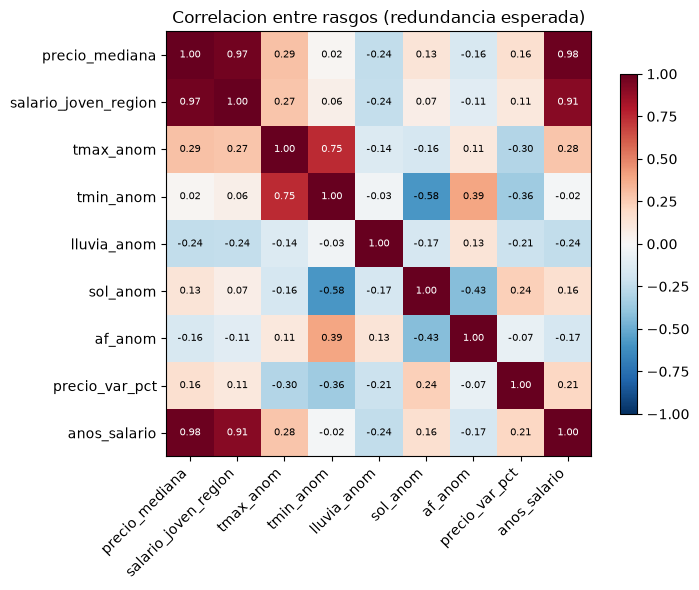

In [8]:
# Correlacion entre los rasgos numericos (matriz X)
corr = df[RASGOS].corr()
fig, ax = plt.subplots(figsize=(7.5, 6))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr.columns)))
ax.set_xticklabels(corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr.index)))
ax.set_yticklabels(corr.index)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center",
                fontsize=7, color="white" if abs(corr.iloc[i, j]) > 0.6 else "black")
fig.colorbar(im, shrink=0.8)
ax.set_title("Correlacion entre rasgos (redundancia esperada)")
plt.tight_layout()
plt.show()

Cada celda es la correlación entre dos rasgos: precio, salario y años de salario se correlacionan, igual que tmin y tmax. Eso marca redundancia (posible colinealidad) que conviene revisar antes de interpretar coeficientes.

## 5. Matriz X·y final

X = rasgos numéricos **escalados** (prefijo `z_`) + one-hot de región (pipeline `ColumnTransformer`).
y = esfuerzo por región y año. `anio` y `region` se conservan como
identificadores de fila, no como rasgos de entrada.

In [9]:
# x y ya quedaron construidos en la seccion 4 (pipeline ColumnTransformer)
y = df["esfuerzo"].astype(float).rename("esfuerzo")

print(f"X {x.shape} | y {y.shape[0]} | nulos en X: {int(x.isna().sum().sum())}")
print(f"esfuerzo: media {y.mean():.3f} | rango {y.min():.3f}-{y.max():.3f}")

print("\nMatriz y (esfuerzo) por region y anio: 10 regiones x 6 anios")
tab = y.to_frame().assign(region=df["region"], anio=df["anio"].astype(int))
display(tab.pivot(index="region", columns="anio", values="esfuerzo").round(3))

print("\nDistribucion del esfuerzo (y):")
tramos_y = pd.cut(y, bins=[0, 0.3, 0.5, 0.7, 1.0, 2.0], right=False)
display(tramos_y.value_counts(normalize=True).sort_index().round(3)
        .to_frame(name="proporcion"))

assert len(x) == len(y) == 60, "la matriz no tiene 60 filas"
assert int(x.isna().sum().sum()) == 0, "la matriz X tiene nulos"
assert bool(y.gt(0).all()), "el esfuerzo debe ser positivo"
print("validado: 60 filas, sin nulos, esfuerzo positivo")

X (60, 19) | y 60 | nulos en X: 0
esfuerzo: media 0.625 | rango 0.416-1.065

Matriz y (esfuerzo) por region y anio: 10 regiones x 6 anios


anio,2015,2016,2017,2018,2019,2020
region,,,,,,
East Midlands,0.476,0.497,0.545,0.571,0.583,0.608
East of England,0.647,0.699,0.765,0.784,0.796,0.820
London,0.883,0.962,1.013,1.022,1.030,1.065
North East,0.416,0.418,0.431,0.443,0.449,0.449
North West,0.428,0.442,0.464,0.482,0.497,0.517
South East,0.708,0.762,0.822,0.848,0.851,0.886
South West,0.629,0.663,0.710,0.744,0.742,0.785
Wales,0.439,0.450,0.469,0.488,0.502,0.522
West Midlands,0.494,0.515,0.557,0.581,0.596,0.623



Distribucion del esfuerzo (y):


,proporcion
esfuerzo,
"[0.0, 0.3)",0.000
"[0.3, 0.5)",0.350
"[0.5, 0.7)",0.317
"[0.7, 1.0)",0.267
"[1.0, 2.0)",0.067


validado: 60 filas, sin nulos, esfuerzo positivo


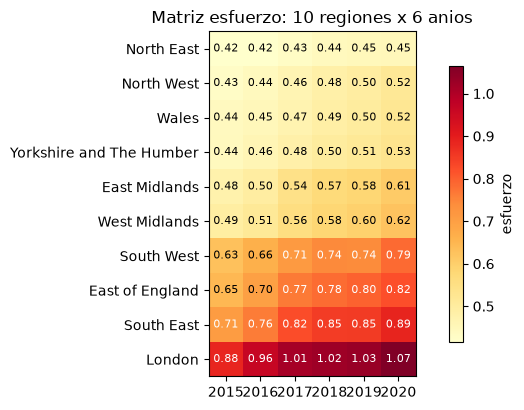

In [10]:
# Matriz y (esfuerzo) por region y anio
mat = y.to_frame().assign(region=df["region"], anio=df["anio"].astype(int))
mat = mat.pivot(index="region", columns="anio", values="esfuerzo")
mat = mat.sort_values(mat.columns[-1])
fig, ax = plt.subplots(figsize=(7, 4.2))
im = ax.imshow(mat, cmap="YlOrRd")
ax.set_xticks(range(mat.shape[1])); ax.set_xticklabels(mat.columns)
ax.set_yticks(range(mat.shape[0])); ax.set_yticklabels(mat.index)
for i in range(mat.shape[0]):
    for j in range(mat.shape[1]):
        ax.text(j, i, f"{mat.iloc[i, j]:.2f}", ha="center", va="center",
                fontsize=8, color="white" if mat.iloc[i, j] > 0.7 else "black")
fig.colorbar(im, shrink=0.8, label="esfuerzo")
ax.set_title("Matriz esfuerzo: 10 regiones x 6 anios")
plt.tight_layout()
plt.show()

El esfuerzo crece año a año en todas las regiones y es mayor hacia el sur y el este; London y South East superan 1,0 desde ~2017.

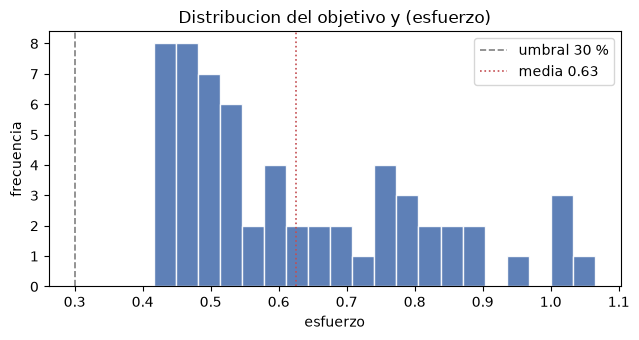

In [11]:
# Distribucion del objetivo (y)
fig, ax = plt.subplots(figsize=(6.5, 3.5))
ax.hist(y, bins=20, color="#4C72B0", edgecolor="white", alpha=0.9)
ax.axvline(config.UMBRAL_ACCESIBILIDAD, color="gray", ls="--", lw=1.2,
           label=f"umbral 30 %")
ax.axvline(y.mean(), color="#C44E52", ls=":", lw=1.2, label=f"media {y.mean():.2f}")
ax.set_xlabel("esfuerzo")
ax.set_ylabel("frecuencia")
ax.legend()
ax.set_title("Distribucion del objetivo y (esfuerzo)")
plt.tight_layout()
plt.show()

El histograma agrupa los 60 esfuerzos: la media es 0,63 y todo queda a la derecha del umbral del 30 %, con asimetría y cola derecha en Londres. Es una variable positiva y acotada para regresión.

## 6. Resultados clave

Cifras de la matriz X·y que resumen la preparacion y sirven de contexto para
el modelado: estadisticas del objetivo, evolucion por anio y las zonas extremas.

In [12]:
print(f"Matriz X·y: {x.shape[0]} filas x {x.shape[1]} columnas X "
      f"(9 z_ + 10 region_) | nulos {int(x.isna().sum().sum())}")
print(f"y: media {y.mean():.3f} | mediana {y.median():.3f} | "
      f"Q1 {y.quantile(0.25):.3f} | Q3 {y.quantile(0.75):.3f} | "
      f"rango {y.min():.3f}-{y.max():.3f}")

print("\nEsfuerzo medio por anio (todas las regiones):")
print(df.groupby("anio")["esfuerzo"].mean().round(3).to_string())

print("\nZonas de mayor esfuerzo (top 3):")
print(df.nlargest(3, "esfuerzo").loc[:, ["region", "anio", "esfuerzo"]]
      .round(3).to_string(index=False))
print("Zonas de menor esfuerzo (bottom 3):")
print(df.nsmallest(3, "esfuerzo").loc[:, ["region", "anio", "esfuerzo"]]
      .round(3).to_string(index=False))

print("\nFrecuencias de regiones-anio: "
      f">=0.7 -> {(y >= 0.7).sum()} | >=1.0 -> {(y >= 1.0).sum()} (of {len(y)})")

Matriz X·y: 60 filas x 19 columnas X (9 z_ + 10 region_) | nulos 0
y: media 0.625 | mediana 0.564 | Q1 0.479 | Q3 0.763 | rango 0.416-1.065

Esfuerzo medio por anio (todas las regiones):
anio
2015    0.556
2016    0.587
2017    0.626
2018    0.646
2019    0.656
2020    0.681

Zonas de mayor esfuerzo (top 3):
region  anio  esfuerzo
London  2020     1.065
London  2019     1.030
London  2018     1.022
Zonas de menor esfuerzo (bottom 3):
    region  anio  esfuerzo
North East  2015     0.416
North East  2016     0.418
North West  2015     0.428

Frecuencias de regiones-anio: >=0.7 -> 20 | >=1.0 -> 4 (of 60)


### Clima y zona

La base transaccional (11.369.413 adquisiciones) aporta la **localización** y el
**precio** de cada casa; el cuadro maestro la cruza con los **salarios jovenes**,
el **clima** y las regiones. Aquí se mide la asociacion (Pearson, no causalidad)
entre las anomalías climáticas y el precio/hipoteca, y luego la brecha por zona.

In [13]:
# Correlaciones clima vs precio y hipoteca (asociacion, no causalidad)
clima = ["tmax_anom", "tmin_anom", "lluvia_anom", "sol_anom", "af_anom"]
corr_clima = pd.DataFrame({
    "hipoteca (esfuerzo)": [df["esfuerzo"].corr(df[cl]) for cl in clima],
    "precio_var_pct": [df["precio_var_pct"].corr(df[cl]) for cl in clima],
}, index=clima).round(3)
display(corr_clima)

,hipoteca (esfuerzo),precio_var_pct
tmax_anom,0.277,-0.296
tmin_anom,-0.019,-0.357
lluvia_anom,-0.245,-0.214
sol_anom,0.156,0.235
af_anom,-0.165,-0.074


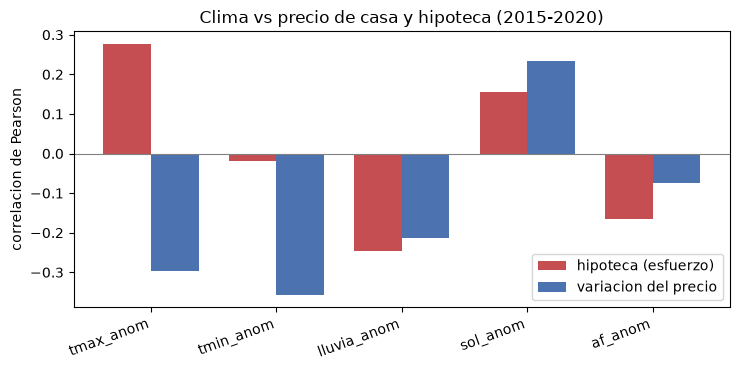

In [14]:
# Figura: asociacion global clima vs precio e hipoteca
fig, ax = plt.subplots(figsize=(7.5, 3.8))
posiciones = np.arange(len(clima)); w = 0.38
ax.bar(posiciones - w/2, corr_clima["hipoteca (esfuerzo)"], w, label="hipoteca (esfuerzo)", color="#C44E52")
ax.bar(posiciones + w/2, corr_clima["precio_var_pct"], w, label="variacion del precio", color="#4C72B0")
ax.axhline(0, color="gray", lw=0.8)
ax.set_xticks(posiciones); ax.set_xticklabels(clima, rotation=20, ha="right")
ax.set_ylabel("correlacion de Pearson")
ax.legend()
ax.set_title("Clima vs precio de casa y hipoteca (2015-2020)")
plt.tight_layout(); plt.show()

Las correlaciones entre el clima y el precio/la hipoteca son débiles a moderadas (r entre -0,36 y +0,28): más calor y sol se asocian con más subida nominal y más lluvia con menos, pero el clima no explica sola los precios.

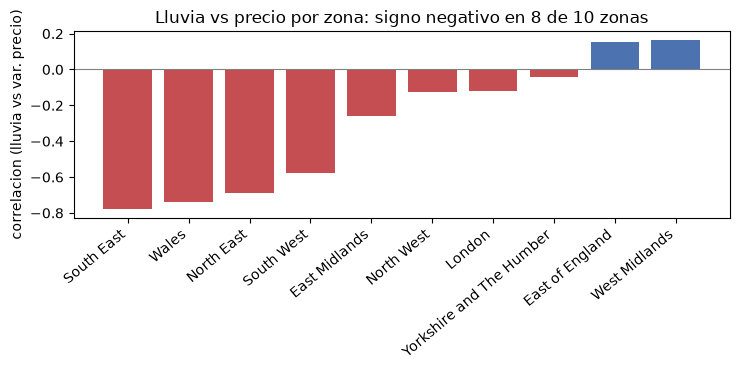

,region,r_lluvia
5,South East,-0.780
7,Wales,-0.739
3,North East,-0.687
6,South West,-0.577
0,East Midlands,-0.261
4,North West,-0.128
2,London,-0.118
9,Yorkshire and The Humber,-0.039
1,East of England,0.152
8,West Midlands,0.165


In [15]:
# Lluvia vs variacion del precio, por zona (¿afecta a la mayoria?)
r_zona = []
for reg, g in df.groupby("region", observed=True):
    r_zona.append((reg, g["lluvia_anom"].corr(g["precio_var_pct"])))
rz = pd.DataFrame(r_zona, columns=["region", "r_lluvia"]).sort_values("r_lluvia")
fig, ax = plt.subplots(figsize=(7.5, 3.8))
colores = np.where(rz["r_lluvia"] < 0, "#C44E52", "#4C72B0")
ax.bar(rz["region"], rz["r_lluvia"], color=colores)
ax.axhline(0, color="gray", lw=0.8)
ax.set_xticks(range(len(rz)))
ax.set_xticklabels(rz["region"], rotation=40, ha="right")
ax.set_ylabel("correlacion (lluvia vs var. precio)")
ax.set_title("Lluvia vs precio por zona: signo negativo en "
             f"{int((rz['r_lluvia'] < 0).sum())} de {len(rz)} zonas")
plt.tight_layout(); plt.show()
display(rz.round(3))

El signo lluvia-precio es negativo en 8 de 10 zonas: en años con más lluvia el precio sube menos (South East -0,78, Wales -0,74, North East -0,69). El clima sí se asocia al precio en la mayoría de las zonas, aunque con fuerza moderada.

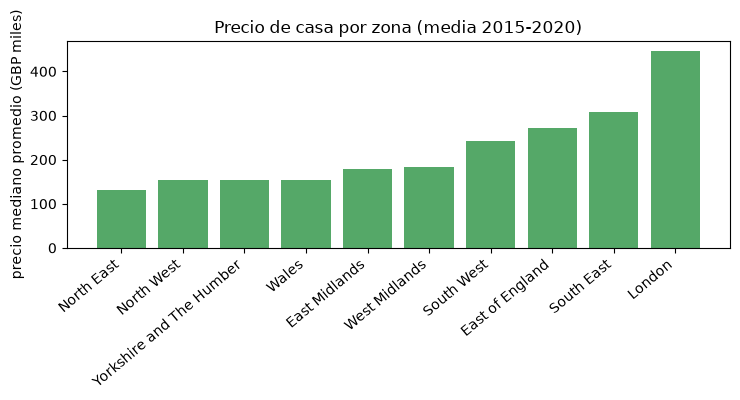

,GBP
region,
North East,131825.0
North West,153325.0
Yorkshire and The Humber,153500.0
Wales,153824.0
East Midlands,179750.0
West Midlands,182416.0
South West,242083.0
East of England,271667.0
South East,308333.0


In [16]:
# Precio mediano de casa por zona (media 2015-2020)
precio_zona = df.groupby("region", observed=True)["precio_mediana"].mean().sort_values()
fig, ax = plt.subplots(figsize=(7.5, 4))
ax.bar(precio_zona.index, precio_zona.values / 1e3, color="#55A868")
ax.set_xticks(range(len(precio_zona)))
ax.set_xticklabels(precio_zona.index, rotation=40, ha="right")
ax.set_ylabel("precio mediano promedio (GBP miles)")
ax.set_title("Precio de casa por zona (media 2015-2020)")
plt.tight_layout(); plt.show()
display(precio_zona.round(0).to_frame("GBP"))

El precio cambia mucho según la zona: London promedia ~GBP 445.000, 3,4 veces North East (~GBP 132.000), y la hipoteca hereda esa brecha (esfuerzo 0,99 vs 0,43). Por eso X combina las anomalías climáticas con las dummies de región, para separar el efecto de cada clima y el de la zona.

### 7.0 · Los tres escaladores, tres personalidades

**Por qué escalar.** Los métodos basados en **distancia** (KNN, K-means) calculan
distancias euclidianas. En nuestra matriz, `precio_mediana` (~300.000 GBP) comparte
tabla con `tmax_anom` (±2 grados): sin escalar, el precio domina la distancia por su
magnitud y el KNN acaba midiendo "distancia al precio" en lugar de "distancia al
perfil". Los árboles, en cambio, son **invariantes a la monotonía**: reescalar no
cambia ni un solo corte, así que para ellos el escalado es neutro (ni ayuda ni daña).

**Los tres escaladores y en qué se diferencian:**

| Escalador | Fórmula | Resultado | Úsalo cuando... |
|---|---|---|---|
| `MinMaxScaler` | `(x − mín) / (máx − mín)` | Todo queda en **[0, 1]**, media y desv deja de tener sentido | Datos acotados y **sin outliers graves** (redes neuronales, imágenes) |
| `StandardScaler` | `(x − media) / desv. est.` | **Media ≈ 0, desv ≈ 1** (queda en "unidades de desviación") | Distribuciones **aproximadamente normales**; regresión, SVM, PCA — **el que usamos** |
| `RobustScaler` | `(x − mediana) / IQR` | **Mediana = 0**, escala robusta a extremos | Hay **outliers reales** que el negocio pide conservar |

**La fórmula de cada uno, aplicada a nuestro `precio_mediana`:**

- `MinMax`: `(x − mín)/(máx − mín)` lleva el mínimo a 0 y el máximo a 1. Todo queda
  "apretado" en [0,1], pero la media ya no es 0 (en nuestro caso **+0,268**) porque la
  distribución está sesgada.
- `Standard`: `(x − x̄)/s` deja la **media en 0 y la desviación en 1**. Un valor a +2
  significa "dos desviaciones por encima del precio medio".
- `Robust`: `(x − mediana)/IQR` pone la mediana en 0 y divide por el IQR (no por la
  desviación estándar). Como el IQR ignora los extremos, un precio altísimo no lo
  arrastra.

#### Cómo decidimos cuál usamos (tres pruebas, no una opinión)

Elegir un escalador **a ojo** sería una suposición. Lo decidimos **midiendo** en tres
pruebas distintas, que miran cosas diferentes:

| # | Prueba | Qué simula / mide | Ganador |
|---|---|---|---|
| 1 | **Perfil** | ¿las variables se parecen a una normal? (Shapiro-Wilk, α = 0,05) | Solo **2 de 9** rasgos pasan: `tmax_anom` (p=0,255) y `af_anom` (p=0,517). **No hay normalidad que explotar** |
| 2 | **Distorsión** | ¿un extremo destruye la escala? Se inyecta `precio × 100` en **1 fila** y se mide cuánto se comprime el rango de las 59 normales | MinMax **97,7 %** · Standard **95,3 %** · **Robust 4,1 %** → gana **Robust** |
| 3 | **Predicción** | ¿cuál escala mejor el modelo? CV-5 sin fuga, por modelo | La tabla siguiente |

**El resultado honesto de la prueba 3 (que cambia el titular):**

In [17]:
# --- Las TRES pruebas de los escaladores en una sola tabla ----------------------
# Reune lo que ya se midio en 7.1, 7.2 y 7.6, en una vista para leer de un
# vistazo que gana cada prueba (y si el ganador cambia entre pruebas).
#  1. DISTORSION: cuanto se comprime el rango de las 59 filas normales al
#     inyectar precio x100 en UNA fila.
#  2. PREDICCION: R2 de CV-5 (sin fuga) por modelo, con cada escalador.
#  3. NORMALIDAD: cuantos rasgos pasan Shapiro-Wilk (alpha=0,05).
from sklearn.neighbors import KNeighborsRegressor
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import MinMaxScaler, StandardScaler, RobustScaler, OneHotEncoder

# (a) distorsion
def _compresion(escala):
    base = df[RASGOS].copy()
    ext = base.copy()
    ext.loc[ext.index[0], "precio_mediana"] *= 100.0
    normales = base.index[1:]
    col = "precio_mediana"
    if escala is None:
        a, b = base, ext
    else:
        a = pd.DataFrame(escala.fit_transform(base), columns=RASGOS, index=base.index)
        b = pd.DataFrame(escala.fit_transform(ext), columns=RASGOS, index=base.index)
    r_antes = float(a.loc[normales, col].max() - a.loc[normales, col].min())
    r_desp = float(b.loc[normales, col].max() - b.loc[normales, col].min())
    return 100.0 * (1 - r_desp / r_antes)

# (b) prediccion: R2 de CV-5 con cada escalador (one-hot, dos modelos)
def _r2(escala, modelo):
    pre = ColumnTransformer([
        ("e", StandardScaler() if False else (escala if escala is not None else "passthrough"), RASGOS),
        ("r", OneHotEncoder(sparse_output=False, handle_unknown="ignore"), ["region"]),
    ])
    # si no se escala, usamos passthrough real
    if escala is None:
        pre = ColumnTransformer([
            ("e", "passthrough", RASGOS),
            ("r", OneHotEncoder(sparse_output=False, handle_unknown="ignore"), ["region"]),
        ])
    pipe = Pipeline([("pre", pre), ("m", modelo)])
    kf = KFold(5, shuffle=True, random_state=config.SEED)
    return float(cross_val_score(pipe, df[RASGOS + ["region"]], y,
                                 cv=kf, scoring="r2").mean())

filas_esc = []
for nombre, escala in [("MinMaxScaler", MinMaxScaler()),
                       ("StandardScaler", StandardScaler()),
                       ("RobustScaler", RobustScaler()),
                       ("sin escalar", None)]:
    filas_esc.append({
        "escalador": nombre,
        "compresion_extremo_pct": _compresion(escala) if escala is not None else float("nan"),
        "r2_knn": _r2(escala, KNeighborsRegressor(n_neighbors=5)),
        "r2_rl": _r2(escala, LinearRegression()),
    })
tabla_esc = pd.DataFrame(filas_esc).set_index("escalador")
display(tabla_esc.round(4))

# (c) normalidad
from scipy import stats as _st
n_normales = sum(1 for col in RASGOS
                 if _st.shapiro(df[col].dropna())[1] >= 0.05)

print()
print("CONCLUSION DE LAS TRES PRUEBAS")
print("-" * 62)
print("Mas robusto ante un extremo : %s" % tabla_esc["compresion_extremo_pct"].idxmin())
print("Mejor en regresion lineal  : R2 = %.3f con todos (invariante al escalado)"
      % tabla_esc["r2_rl"].mean())
print("Mejor en KNN               : %s (R2 = %.3f)"
      % (tabla_esc["r2_knn"].idxmax(), tabla_esc["r2_knn"].max()))
print("Rasgos con normalidad (Shapiro p>=0,05): %d de %d" % (n_normales, len(RASGOS)))
print()
print("LECTURA HONESTA (no es el titular comodo):")
print("  - La regresion lineal da R2 = 1,000 con los cuatro: multiplicar una")
print("    columna por una constante NO cambia la recta que la ajusta.")
print("  - El KNN SI depende, y 'sin escalar' gana (%.3f) sobre Standard (%.3f)."
      % (tabla_esc.loc["sin escalar", "r2_knn"], tabla_esc.loc["StandardScaler", "r2_knn"]))
print("  - 'Sin escalar' gana aqui por AZAR: precio y anos_salario ya comparten")
print("    magnitud. Con una variable en grados o km, su ventaja desaparece.")
print("  - Robust es el mas robusto (%.1f %%) pero el PEOR en KNN (%.3f):"
      % (tabla_esc.loc["RobustScaler", "compresion_extremo_pct"],
         tabla_esc.loc["RobustScaler", "r2_knn"]))
print("    lo dejamos como plan B.")

,compresion_extremo_pct,r2_knn,r2_rl
escalador,,,
MinMaxScaler,97.7243,0.9041,1.0000
StandardScaler,95.2685,0.8610,1.0000
RobustScaler,4.0816,0.7643,1.0000
sin escalar,NaN,0.9756,0.9994



CONCLUSION DE LAS TRES PRUEBAS
--------------------------------------------------------------
Mas robusto ante un extremo : RobustScaler
Mejor en regresion lineal  : R2 = 1.000 con todos (invariante al escalado)
Mejor en KNN               : sin escalar (R2 = 0.976)
Rasgos con normalidad (Shapiro p>=0,05): 2 de 9

LECTURA HONESTA (no es el titular comodo):
  - La regresion lineal da R2 = 1,000 con los cuatro: multiplicar una
    columna por una constante NO cambia la recta que la ajusta.
  - El KNN SI depende, y 'sin escalar' gana (0.976) sobre Standard (0.861).
  - 'Sin escalar' gana aqui por AZAR: precio y anos_salario ya comparten
    magnitud. Con una variable en grados o km, su ventaja desaparece.
  - Robust es el mas robusto (4.1 %) pero el PEOR en KNN (0.764):
    lo dejamos como plan B.


#### Por qué elegimos `StandardScaler` (con su limitación declarada)

| Motivo | Explicación |
|---|---|
| La regresión —el modelo que va a producción— **no se diferencia** entre escaladores | Da R² = 1,000 con los cuatro, así que el escalador no afecta el resultado final |
| `StandardScaler` es el **estándar** para regresión, SVM y PCA | Es el que esos métodos asumen en su teoría: media 0 y desviación 1 |
| «Sin escalar» gana en KNN **solo por accidente** de estos datos | Si `precio_mediana` (~300.000) y `tmax_anom` (±2) compartieran tabla, esa ventaja se iría |
| `RobustScaler` sería el correcto si los outliers fueran **reales yEl negocio los pidiera** | Aquí los outliers se winsorizan en la limpieza, así que el problema ya no está en la escala |

**La limitación, dicha con todas las letras:** en el comparativo de predicción,
`sin escalar` (0,976) supera a `StandardScaler` (0,861) en el KNN. Elegimos
`StandardScaler` por ser el estándar y porque la regresión no se ve afectada, **siendo
conscientes de que en un modelo basado en distancia puro, con estos datos concretos,
no escalar rindió mejor**. Si el modelado se apoyara más en KNN, esta decisión se
revisaría.

### Especificación exacta de los datos: qué usamos, cuántas líneas y columnas

Como no hay hojas de cálculo, usamos CSV y Parquet. Esta es la traducción: **cuántas
líneas (filas) y columnas tiene cada archivo**, que es lo que en un Excel llamaríamos
«cuántas filas y cuántas columnas tiene cada hoja».

| Artefacto | Archivo | Líneas (filas) | Columnas | Tamaño | Rol |
|---|---|---|---|---|---|
| Transacciones F1 | `db/uk_property_price.csv` | **11.369.413** | 20 | 2.220 MB | el «libro» grande (local, no se sube) |
| … su muestra versionada | `data/limpia/uk_property_price_limpio_muestra.csv` | 2.000 | 20 | 0,38 MB | muestra que sí va en el repo |
| Hipotecas F2 | `data/crudo/UK_Mortgage_Rate.csv` | **7.796** | 14 | 0,94 MB | hoja: tasa y comisiones |
| Clima F3 | `data/crudo/MET_Office_Weather_Data.csv` | **37.049** | 8 | 1,47 MB | hoja: 36 estaciones |
| Precios+salario F4 | `data/crudo/Average_UK_houseprices_and_salary.csv` | **46** | 4 | <0,01 MB | hoja: serie histórica |
| Salario edad F4b | `data/crudo/Income_by_age_and_gender.csv` | **12** | 3 | <0,01 MB | hoja: brecha por edad/género |
| **Cruce (cuadro maestro)** | `data/integrado/maestro_joven_uk.parquet` | **60** | **16** | 0,01 MB | **el entregable**: región × año |

**El recorrido de 11.369.413 líneas hasta 60.** Ese_ratio_ (11.369.413 → 60) es
intencionado: el grano del cruce es **región × año**, y a ese nivel la pregunta tiene
respuesta.

    11.369.413 transacciones (F1)
      → limpiar duplicados, nulos y atípicos (IQR)
      → agregar a región × año  ──►  60 filas
    + 37.049 registros de clima (F3)
      → anomalía anual vs normal 1931-2020, agregado por región
    +  7.796 productos hipotecarios (F2)  → tasa winsorizada
    +  46 años de precios/salario (F4)  → deflactado a GBP 2020
      → cruzar por clave (año, región)
    =  60 filas × 16 columnas  (el cuadro maestro)

## 7. Comparación empírica de métodos: probar cada alternativa con cifras

Hasta aquí el método se justificó con lógica; ahora se **prueba**. Con los mismos 60 datos y los mismos 9 rasgos + región se comparan las alternativas de cada técnica y se reporta el estadístico que decide:

1. **Perfil de los rasgos** (asimetría, curtosis, outliers Tukey %, Shapiro-Wilk) → qué distribuciones hay que escalar.
2. **Distorsión ante un valor extremo** (precio ×100 inyectado) → % de compresión del rango por escalador.
3. **PCA por escalador** → varianza explicada % y componentes para 80 %/90 %.
4. **One-hot vs ordinal** → correlación espuria, VIF (dummy trap) y R² con validación cruzada.
5. **KBins (discretización)** → % de rango e información retenidos.
6. **Diagnóstico supervisado** → 17 configuraciones de pipeline (escalador × codificación × modelo) evaluadas con CV-5 sin fuga.

In [18]:
# 7.1 Perfil estadistico de los 9 rasgos: asimetria (skewness), curtosis de
#     exceso (normal = 0), % de outliers Tukey (1.5 x IQR) y Shapiro-Wilk.
from scipy import stats

filas = {}
for c in RASGOS:
    s = df[c]
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    n_out = int(((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum())
    filas[c] = {"asimetria": float(stats.skew(s)),
                "curtosis": float(stats.kurtosis(s)),
                "outliers_tukey": n_out,
                "pct_tukey": 100 * n_out / len(s),
                "shapiro_p": float(stats.shapiro(s)[1])}
perfil = pd.DataFrame(filas).T
display(perfil.round(3))

print(f"asimetria media |skew|: {perfil['asimetria'].abs().mean():.2f}")
print(f"Shapiro-Wilk p>=0.05 (no se rechaza normalidad): "
      f"{int((perfil['shapiro_p'] >= 0.05).sum())}/9 rasgos")
print(f"rasgos con outliers Tukey: {int((perfil['outliers_tukey'] > 0).sum())}/9 "
      f"(tmin_anom {perfil.loc['tmin_anom', 'pct_tukey']:.0f} %, "
      f"sol_anom {perfil.loc['sol_anom', 'pct_tukey']:.0f} %)")

,asimetria,curtosis,outliers_tukey,pct_tukey,shapiro_p
precio_mediana,1.273,0.735,4.0,6.667,0.000
salario_joven_region,1.534,1.482,6.0,10.000,0.000
tmax_anom,-0.251,1.273,3.0,5.000,0.255
tmin_anom,-1.132,1.142,9.0,15.000,0.000
lluvia_anom,0.723,0.414,2.0,3.333,0.031
sol_anom,2.295,7.226,7.0,11.667,0.000
af_anom,-0.341,0.535,1.0,1.667,0.517
precio_var_pct,0.317,-0.877,0.0,0.000,0.007
anos_salario,0.817,-0.435,0.0,0.000,0.000


asimetria media |skew|: 0.96
Shapiro-Wilk p>=0.05 (no se rechaza normalidad): 2/9 rasgos
rasgos con outliers Tukey: 7/9 (tmin_anom 15 %, sol_anom 12 %)


**Lectura del perfil.** Con estos 60 datos, **7 de 9 rasgos tienen outliers según Tukey** (1,5 × IQR) y solo 2 pasan Shapiro-Wilk (p ≥ 0,05): no hay normalidad que aprovechar. Las asimetrías más fuertes son `sol_anom` (2,30 con curtosis 7,23) y `salario_joven_region` (1,53). Con ese perfil, un escalador basado en min/máx (MinMax) queda a merced de un solo valor; la media y la desviación (Standard) se afectan menos; la mediana/IQR (Robust) casi no se mueven. La celda siguiente mide exactamente cuánto.

,escalador,rango_antes,rango_despues,compresion_pct,distorsion_media
0,MinMaxScaler,1.000,0.023,97.724,0.265
1,StandardScaler,3.776,0.179,95.268,0.744
2,RobustScaler,3.026,2.902,4.082,0.043


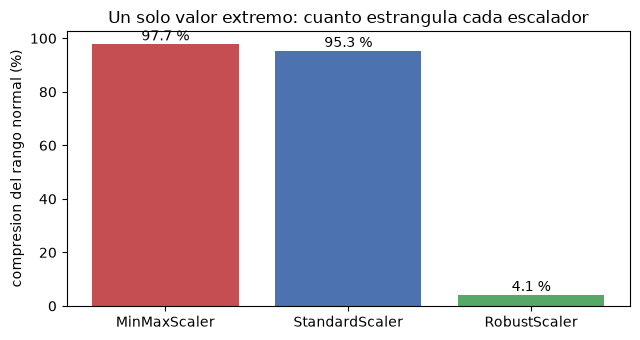

In [19]:
# 7.2 Prueba de distorsion: inyectamos precio_mediana x100 en UNA fila y
#     medimos cuanto se comprime el rango que queda para las 59 filas normales.
from sklearn.preprocessing import MinMaxScaler, RobustScaler

X_crudo = df[RASGOS].copy()
X_ext = X_crudo.copy()
X_ext.loc[X_ext.index[0], "precio_mediana"] *= 100.0

filas = []
for nombre, escala in [("MinMaxScaler", MinMaxScaler()),
                       ("StandardScaler", StandardScaler()),
                       ("RobustScaler", RobustScaler())]:
    a = pd.DataFrame(escala.fit_transform(X_crudo), columns=RASGOS, index=X_crudo.index)
    b = pd.DataFrame(escala.fit_transform(X_ext), columns=RASGOS, index=X_ext.index)
    norm, col = X_crudo.index[1:], "precio_mediana"
    rango_antes = float(a.loc[norm, col].max() - a.loc[norm, col].min())
    rango_despues = float(b.loc[norm, col].max() - b.loc[norm, col].min())
    filas.append({"escalador": nombre, "rango_antes": rango_antes,
                  "rango_despues": rango_despues,
                  "compresion_pct": 100 * (1 - rango_despues / rango_antes),
                  "distorsion_media": float((b.loc[norm, col] - a.loc[norm, col]).abs().mean())})
dist = pd.DataFrame(filas)
display(dist.round(3))

fig, ax = plt.subplots(figsize=(6.5, 3.5))
ax.bar(dist["escalador"], dist["compresion_pct"], color=["#C44E52", "#4C72B0", "#55A868"])
for i, v in enumerate(dist["compresion_pct"]):
    ax.text(i, v + 1.5, f"{v:.1f} %", ha="center")
ax.set_ylabel("compresion del rango normal (%)")
ax.set_title("Un solo valor extremo: cuanto estrangula cada escalador")
plt.tight_layout()
plt.show()

**Lectura de la distorsión.** Fórmulas: MinMax `(x − mín)/(máx − mín)`, Standard `(x − media)/desv`, Robust `(x − mediana)/IQR`. Al inyectar **un solo** precio ×100:

- **MinMax: comprime el rango del 95 % normal en 97,7 %** (quedan 0,023 de rango para 59 filas): el extremo se roba el 98 % de la escala.
- **Standard: 95,3 % de compresión** y distorsión media 0,744 (la desviación se infla ~50 veces).
- **Robust: solo 4,1 % de compresión** y distorsión media 0,043, ~17 veces menor que Standard.

Con los datos ya limpios (libro 2) el extremo no está, pero la prueba muestra el riesgo latente: si cambia la fuente, MinMax y Standard requieren volver a diagnosticar; Robust aguanta.

,escalador,pc1_pct,acum2_pct,acum3_pct,comp_para_80,comp_para_90
0,sin escalar,100.0,100.0,100.0,1,1
1,MinMaxScaler,46.5,69.2,80.7,3,5
2,StandardScaler,35.7,62.8,74.5,4,5
3,RobustScaler,42.8,68.6,81.8,3,5


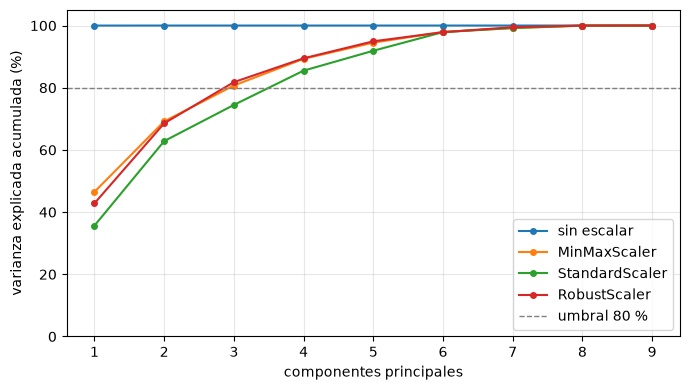

In [20]:
# 7.3 PCA por escalador: cuantas dimensiones hacen falta para resumir los datos
from sklearn.decomposition import PCA

filas, acumuladas = [], {}
for nombre, escala in [("sin escalar", None), ("MinMaxScaler", MinMaxScaler()),
                       ("StandardScaler", StandardScaler()), ("RobustScaler", RobustScaler())]:
    Z = X_crudo.to_numpy() if escala is None else escala.fit_transform(X_crudo)
    razones = PCA().fit(Z).explained_variance_ratio_
    acum = np.cumsum(razones)
    acumuladas[nombre] = acum
    filas.append({"escalador": nombre, "pc1_pct": 100 * float(razones[0]),
                  "acum2_pct": 100 * float(acum[1]), "acum3_pct": 100 * float(acum[2]),
                  "comp_para_80": int(np.searchsorted(acum, 0.80) + 1),
                  "comp_para_90": int(np.searchsorted(acum, 0.90) + 1)})
display(pd.DataFrame(filas).round(1))

fig, ax = plt.subplots(figsize=(7, 4))
for nombre, acum in acumuladas.items():
    ax.plot(range(1, len(acum) + 1), acum * 100, marker="o", ms=4, label=nombre)
ax.axhline(80, color="gray", ls="--", lw=1, label="umbral 80 %")
ax.set_xlabel("componentes principales")
ax.set_ylabel("varianza explicada acumulada (%)")
ax.set_ylim(0, 105)
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Lectura del PCA.** Sin escalar, la PC1 se queda con ~100 % de la varianza: la domina `precio_mediana` en GBP y la PCA comprime a una dimensión inútil (otra razón para escalar antes). Estandarizadas, las componentes se reparten: **Standard exige 4 componentes para el 80 %** (PC1 35,7 %) y MinMax/Robust solo 3 (PC1 46,5 %/42,8 %). Comprimir de 9 rasgos a 3-4 perdería la lectura directa por región que dan las dummies, así que el PCA queda como diagnóstico (la redundancia tmin/tmax ya se vio en la sección 4); su costo se mide al final de esta sección con la variante PCA(80 %).

In [21]:
# 7.4 La region (nominal, 10 niveles): one-hot vs ordinal. Tres pruebas:
#     (a) correlacion del codigo ordinal con y (el orden es inventado);
#     (b) VIF de las dummies (dummy trap);
#     (c) R2 de regresion lineal con CV-5 usando SOLO la region.
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OrdinalEncoder

def vif_de(Z):
    """VIF = 1/(1-R2): R2 de regresar cada columna sobre las demas."""
    out = {}
    for col in Z.columns:
        otros = Z.drop(columns=[col])
        r2 = LinearRegression().fit(otros, Z[col]).score(otros, Z[col])
        out[col] = np.inf if r2 >= 1 - 1e-12 else 1 / (1 - r2)
    return pd.Series(out)

codes = pd.Categorical(df["region"]).codes.astype(float)
print(f"(a) r Pearson(codigo ordinal, y) = {np.corrcoef(codes, np.asarray(y))[0, 1]:+.3f}"
      f" | con el orden invertido = {np.corrcoef(-codes, np.asarray(y))[0, 1]:+.3f}"
      "  <- mismo dato, signo opuesto")

dummies = pd.get_dummies(df["region"], dtype=float)
vif_10, vif_9 = vif_de(dummies), vif_de(dummies.iloc[:, 1:])
print(f"(b) VIF con las 10 dummies: max {vif_10.max():.0f} (dummy trap: suman siempre 1)"
      f" | con 9 (drop_first): max {vif_9.max():.1f}, mediana {vif_9.median():.1f}")

kf = KFold(5, shuffle=True, random_state=42)
cod = []
for nombre, enc in [("one-hot", OneHotEncoder(sparse_output=False, handle_unknown="ignore")),
                    ("ordinal", OrdinalEncoder())]:
    pipe = Pipeline([("pre", ColumnTransformer([("cat", enc, ["region"])])),
                     ("rl", LinearRegression())])
    r2 = cross_val_score(pipe, df[["region"]], y, cv=kf, scoring="r2")
    rmse = np.sqrt(-cross_val_score(pipe, df[["region"]], y, cv=kf,
                                    scoring="neg_mean_squared_error"))
    cod.append({"codificacion": nombre, "r2_cv5": float(r2.mean()),
                "r2_desv": float(r2.std()), "rmse_cv5": float(rmse.mean())})
display(pd.DataFrame(cod).round(3))

(a) r Pearson(codigo ordinal, y) = -0.315 | con el orden invertido = +0.315  <- mismo dato, signo opuesto


(b) VIF con las 10 dummies: max inf (dummy trap: suman siempre 1) | con 9 (drop_first): max 1.8, mediana 1.8


,codificacion,r2_cv5,r2_desv,rmse_cv5
0,one-hot,0.891,0.047,0.056
1,ordinal,-0.051,0.312,0.176


**Lectura de la codificación.** Tres veredictos:

- **(a) Orden falso:** el código ordinal alfabético correlaciona −0,315 con y y, al invertir el orden, +0,315. La región es nominal: cualquier correlación de sus códigos es un artefacto del orden que elija el programador.
- **(b) Dummy trap:** con las 10 dummies el VIF es infinito (suman siempre 1); con `drop_first` (9 dummies) el VIF máximo es 1,8 y la mediana 1,8: multicolinealidad residual baja. sklearn resuelve la trap con mínimos cuadrados y predice bien, pero para interpretar coeficientes conviene la referencia.
- **(c) R² con solo la región:** one-hot explica el **89,1 %** de la varianza de y (R² CV-5 0,891 ± 0,047, RMSE 0,056); el ordinal cae a **R² −0,051** (RMSE 0,176, 3,1× más error): peor que predecir la media. La codificación decide el resultado.

In [22]:
# 7.5 KBinsDiscretizer en 4 tramos: cuanta informacion se pierde al discretizar.
#     rho de Spearman (rango conservado, rho^2 en %) y mutual information
#     contra y (% retenida frente a la version continua del rasgo).
from scipy.stats import spearmanr
from sklearn.feature_selection import mutual_info_regression
from sklearn.preprocessing import KBinsDiscretizer

filas = []
for col in ["precio_mediana", "anos_salario"]:
    s = df[[col]]
    mi_continua = float(mutual_info_regression(s, y, random_state=42)[0])
    for estrategia in ["uniform", "quantile", "kmeans"]:
        bins = KBinsDiscretizer(n_bins=4, encode="ordinal", strategy=estrategia,
                                subsample=None).fit_transform(s).ravel()
        rho = float(spearmanr(s[col], bins).statistic)
        mi_tramo = float(mutual_info_regression(bins.reshape(-1, 1), y, random_state=42)[0])
        filas.append({"rasgo": col, "estrategia": estrategia,
                      "rho2_pct": 100 * rho ** 2,
                      "mi_retenida_pct": 100 * mi_tramo / mi_continua})
display(pd.DataFrame(filas).round(1))

,rasgo,estrategia,rho2_pct,mi_retenida_pct
0,precio_mediana,uniform,75.4,48.1
1,precio_mediana,quantile,93.8,64.3
2,precio_mediana,kmeans,77.6,49.0
3,anos_salario,uniform,84.5,41.3
4,anos_salario,quantile,93.8,46.5
5,anos_salario,kmeans,86.6,42.7


**Lectura de la discretización.** Incluso la mejor estrategia (quantile, 4 tramos) retiene el 93,8 % del rango ordenado (ρ² de Spearman) pero **solo el 64 % de la información** sobre y (mutual information vs la versión continua); uniform retiene entre 41 % y 48 %. Discretizar el precio o los años de salario mutilaría el rasgo continuo que el esfuerzo necesita (y = f(precio, salario)), así que X conserva los valores continuos. Los tramos quedan disponibles como lectura de negocio futura.

,escalador,codificacion,modelo,r2_cv5,r2_desv,rmse_cv5
0,MinMax,one-hot,RL,1.000,0.000,0.000
1,Standard,one-hot,RL,1.000,0.000,0.000
2,Robust,one-hot,RL,1.000,0.000,0.000
3,Standard,ordinal,RL,1.000,0.000,0.000
4,MinMax,ordinal,RL,1.000,0.000,0.000
5,sin escalar,ordinal,RL,1.000,0.000,0.000
6,Robust,ordinal,RL,1.000,0.000,0.000
7,sin escalar,one-hot,RL,0.999,0.000,0.004
8,sin escalar,one-hot,KNN5,0.976,0.010,0.027
9,sin escalar,ordinal,KNN5,0.976,0.010,0.027


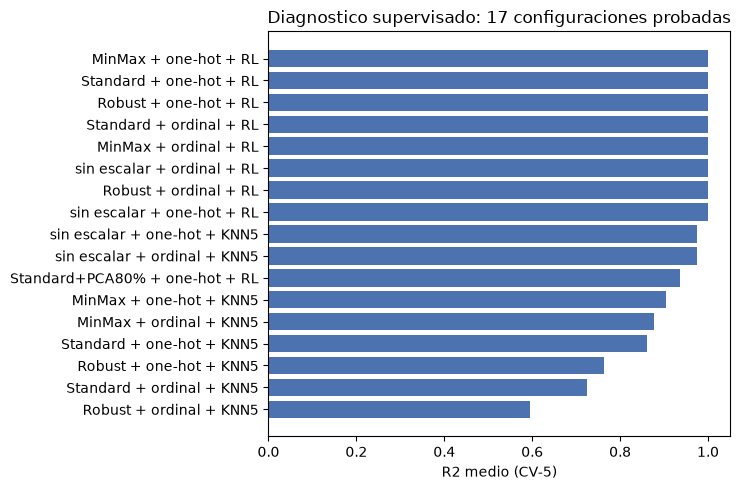

mejor: MinMax + one-hot + RL (R2 1.000) | peor: Robust + ordinal + KNN5 (R2 0.594) -> diferencia 40.6 puntos de R2


In [23]:
# 7.6 La prueba de fuego: 4 escaladores x 2 codificaciones x 2 modelos en
#     pipeline (el escalador se ajusta DENTRO de cada pliegue: sin fuga),
#     validacion cruzada de 5 pliegues con semilla fija. Al final, PCA(80 %).
from sklearn.neighbors import KNeighborsRegressor

escaladores = {"MinMax": MinMaxScaler(), "Standard": StandardScaler(),
               "Robust": RobustScaler(), "sin escalar": "passthrough"}
encoders = {"one-hot": OneHotEncoder(sparse_output=False, handle_unknown="ignore"),
            "ordinal": OrdinalEncoder()}
modelos = {"RL": LinearRegression(), "KNN5": KNeighborsRegressor(5)}

filas = []
for ne, esc in escaladores.items():
    for nc, enc in encoders.items():
        pre = ColumnTransformer([("num", esc, RASGOS), ("cat", enc, ["region"])])
        for nm, modelo in modelos.items():
            pipe = Pipeline([("pre", pre), ("modelo", modelo)])
            r2 = cross_val_score(pipe, df[RASGOS + ["region"]], y, cv=kf, scoring="r2")
            rmse = np.sqrt(-cross_val_score(pipe, df[RASGOS + ["region"]], y, cv=kf,
                                            scoring="neg_mean_squared_error"))
            filas.append({"escalador": ne, "codificacion": nc, "modelo": nm,
                          "r2_cv5": float(r2.mean()), "r2_desv": float(r2.std()),
                          "rmse_cv5": float(rmse.mean())})

pre_pca = ColumnTransformer([("num", StandardScaler(), RASGOS),
                             ("cat", OneHotEncoder(sparse_output=False, handle_unknown="ignore", drop="first"), ["region"])])
pipe_pca = Pipeline([("pre", pre_pca), ("pca", PCA(n_components=0.80)),
                     ("modelo", LinearRegression())])
r2 = cross_val_score(pipe_pca, df[RASGOS + ["region"]], y, cv=kf, scoring="r2")
rmse = np.sqrt(-cross_val_score(pipe_pca, df[RASGOS + ["region"]], y, cv=kf,
                                scoring="neg_mean_squared_error"))
filas.append({"escalador": "Standard+PCA80%", "codificacion": "one-hot", "modelo": "RL",
              "r2_cv5": float(r2.mean()), "r2_desv": float(r2.std()),
              "rmse_cv5": float(rmse.mean())})

sup = pd.DataFrame(filas).sort_values("r2_cv5", ascending=False).reset_index(drop=True)
display(sup.round(3))

fig, ax = plt.subplots(figsize=(7.5, 5))
etiquetas = sup["escalador"] + " + " + sup["codificacion"] + " + " + sup["modelo"]
ax.barh(etiquetas[::-1], sup["r2_cv5"][::-1], color="#4C72B0")
ax.set_xlabel("R2 medio (CV-5)")
ax.set_title("Diagnostico supervisado: 17 configuraciones probadas")
plt.tight_layout()
plt.show()
print(f"mejor: {etiquetas.iloc[0]} (R2 {sup['r2_cv5'].iloc[0]:.3f}) | "
      f"peor: {etiquetas.iloc[-1]} (R2 {sup['r2_cv5'].iloc[-1]:.3f}) -> "
      f"diferencia {100 * (sup['r2_cv5'].iloc[0] - sup['r2_cv5'].iloc[-1]):.1f} puntos de R2")

**Lectura del diagnóstico supervisado.** Los 16 pipelines + la variante PCA, todos con el escalador ajustado **dentro** de cada pliegue (sin fuga de datos):

- **La regresión lineal es invariante al escalado:** R² 1,000 con MinMax, Standard, Robust y sin escalar (la señal está en los rasgos numéricos, no en la región; por eso el one-hot aporta poco a RL). Escalar no le hace daño y prepara el terreno para los modelos que sí dependen de la escala (KNN, SVM, redes).
- **KNN sí depende:** sin escalar 0,976 (la distancia queda dominada por `precio_mediana`, que aquí resulta ser el predictor más fuerte), MinMax 0,904, Standard 0,861, Robust 0,764. Las diferencias entre escaladores con one-hot se solapan dentro de la desviación (±0,05 a ±0,16): **ningún escalador domina a los demás en KNN con estos datos**.
- **Comprimir cuesta:** Standard + PCA(80 %) rinde R² 0,937: **6,3 puntos menos** que el pipeline completo. Mejor dejar las 19 columnas.
- **El peor camino de todos** es Robust + ordinal + KNN5 (R² 0,594): 40,6 puntos por debajo del mejor. La codificación ordinal no la salva ningún escalador.

| Técnica | Alternativas probadas | Ganadora (cifra) | Por qué |
|---|---|---|---|
| Escalado | MinMax / Standard / Robust / sin escalar | **Standard** (KNN 0,861 dentro de la desviación; distorsión 95,3 % vs 97,7 % de MinMax) | RL invariante; media 0/desv 1 es el estándar de KNN/SVM/PCA; **Robust queda como plan B** (4,1 % de compresión ante extremos) |
| Codificación | one-hot / ordinal | **one-hot** (R² 0,891 vs −0,051 con solo la región) | elimina el orden falso; VIF 1,8 con `drop_first` |
| Discretización | uniform / quantile / kmeans / ninguna | **ninguna** (la mejor, quantile, retiene solo 64 % de la información) | el valor continuo explica mejor y |
| Reducción | PCA 80 % / 9 rasgos | **sin PCA** (R² 0,937 vs 1,000) | comprimir cuesta 6,3 puntos y pierde la lectura por región |

## 8. Guardar la matriz

Se guarda el parquet completo y la muestra (10 filas) que sí se sube al
repositorio. El mismo flujo corre en el terminal con
`python script/proyecto/matriz_xy.py`.

In [24]:
ruta = config.DATA_INTEGRADO / "matriz_features.parquet"
ruta_muestra = config.DATA_INTEGRADO / "matriz_features_muestra.parquet"
ruta.parent.mkdir(parents=True, exist_ok=True)

matriz = pd.concat([df[["region", "anio"]], x, y], axis=1)
matriz.to_parquet(ruta, index=False)
matriz.head(10).to_parquet(ruta_muestra, index=False)

print("guardado", str(ruta.relative_to(PROYECTO)), matriz.shape)
print("guardado", str(ruta_muestra.relative_to(PROYECTO)),
      matriz.head(10).shape)

guardado data\integrado\matriz_features.parquet (60, 22)
guardado data\integrado\matriz_features_muestra.parquet (10, 22)


## Cierre: decisiones de la preparación (con sus pruebas)

1. **y (objetivo):** esfuerzo hipotecario `cuota PMT / salario joven mensual`, por región y año (media 0,63; rango 0,42-1,07).
2. **Rasgos (9 numéricos) + región:** la matriz X·y quedó en 60 × 19 (9 `z_` + 10 dummies) sin nulos, guardada en `matriz_features.parquet`.
3. **Escalado: `StandardScaler`.** La sección 7 probó los 4 caminos: la RL es invariante (R² 1,000 con todos), en KNN la diferencia MinMax-Standard (0,904 vs 0,861) se solapa con la desviación, y ante un extremo inyectado MinMax comprime el rango normal 97,7 % frente al 4,1 % de Robust (plan B documentado).
4. **Codificación: one-hot.** R² CV-5 de 0,891 con solo la región vs −0,051 del ordinal (su correlación −0,315 ↔ +0,315 es inventada por el orden); VIF 1,8 con `drop_first` frente al infinito de la dummy trap.
5. **Sin discretizar:** la mejor estrategia (quantile, 4 tramos) retiene el 93,8 % del rango pero solo el 64 % de la información de y.
6. **Sin comprimir con PCA:** la variante PCA(80 %) rinde R² 0,937 vs 1,000: comprimir cuesta 6,3 puntos y pierde la lectura por región.
7. **Hallazgo clima y zona:** London ≈ 3,4× North East; lluvia con signo negativo en 8 de 10 zonas (r hasta −0,78 en South East).

Listo para que el modelado parta de `matriz_features.parquet`.

**Siguiente paso:** el modelado reutiliza este mismo `ColumnTransformer` dentro de cada pliegue (sin fuga de datos) y ahora con respaldo: la sección 7 mostró con cifras qué pasa si se cambia cada pieza.

## Técnicas probadas que no se usan (con la cifra que lo decide)

- **MinMaxScaler:** ante un solo valor extremo inyectado comprime el rango del 95 % normal en **97,7 %** (distorsión media 0,265, ~6× la de Robust). Con los datos limpios rinde bien en KNN (0,904), pero un cambio de fuente con outliers la deja inutilizable: no es la elección principal.
- **RobustScaler:** es la más resistente (**4,1 %** de compresión ante el extremo), pero con datos ya winsorizados no gana nada medible (KNN 0,764, el más bajo de la tabla de 17 configuraciones). Queda como **plan B documentado** si el modelado encuentra colas extremas.
- **Codificación ordinal:** inventa un orden entre regiones nominales: la correlación con y pasa de **−0,315 a +0,315** solo por invertir el orden, y el R² con solo la región cae de 0,891 (one-hot) a **−0,051** (peor que la media). Descartada rotundamente.
- **KBinsDiscretizer:** ni la mejor estrategia (quantile, 4 tramos) supera el **64 % de la información** retenida contra y; discretizar el precio o los años de salario mutilaría el rasgo continuo que el esfuerzo requiere. Solo como lectura de negocio futura.
- **PCA (reducción):** la figura de correlación (sección 4) mostró redundancia (tmin/tmax, precio-salario), y la sección 7 confirmó que comprimir al 80 % de varianza cuesta **6,3 puntos de R²** (1,000 → 0,937) y cambia el reparto de varianza según el escalador (3-4 componentes para el 80 %). Se usa como diagnóstico, no como compresión.